<div style="background:#174D75;color:#F8F5E4;padding:18px 22px;border-radius:4px">
<h1 style="margin:0;font-family:Montserrat,Arial,sans-serif;letter-spacing:1px">HOOPMIND · ¿CÓMO VAMOS?</h1>
<div style="margin-top:6px">Big Data + IA con datos de la NBA · Informe de progreso de la <b>Entrega 2</b> · lunes 23/11/2026</div>
</div>

Este notebook enseña **lo que ya funciona**, con los **resultados reales** de nuestros ficheros y logs (nada está inventado). Lo que todavía no está ejecutado lo marcamos como **pendiente**, y al final hay una sección «Qué falta» sin maquillar.

**Cómo leerlo:** cada sección tiene un texto corto, una celda de código ya ejecutada y, debajo, una nota «En cristiano» que explica el resultado con palabras sencillas.

In [1]:
import json, re, pathlib, importlib.util, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
warnings.filterwarnings("ignore")

# Paleta HoopMind (docs/PALETA_HOOPMIND.md)
CREMA, AZUL, GRANATE = "#F8F5E4", "#174D75", "#21060A"
AZUL_CLARO, GRANATE_CLARO, CREMA_OSC = "#DCE7EF", "#E8D9DC", "#EFE9CF"
plt.rcParams.update({"figure.facecolor": CREMA, "axes.facecolor": CREMA, "axes.edgecolor": GRANATE,
                     "axes.labelcolor": GRANATE, "text.color": GRANATE, "xtick.color": GRANATE, "ytick.color": GRANATE,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "savefig.facecolor": CREMA})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

RAIZ = pathlib.Path(".").resolve()            # raíz del repo (si se abre desde notebooks/, sube un nivel)
if not (RAIZ / "scripts").exists():
    RAIZ = RAIZ.parent
RAW = RAIZ / "data" / "raw_2026-11-17"        # CSV originales de Kaggle (copia de /nba/raw)
SUCIO = RAIZ / "data" / "dirty"               # salida de ensuciar.py
CURADO = RAIZ / "data" / "curated_export"     # exportación de curated a CSV (la crea pipeline_limpieza.sh)
LOGS = RAIZ / "logs"

def ev(nombre):
    """Evidencia pequeña: primero en logs/ (tu PC); si no, la copia guardada en docs/evidencias_entrega2/."""
    for carpeta in (LOGS, RAIZ / "docs" / "evidencias_entrega2"):
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(nombre)

print("Carpeta de trabajo:", RAIZ)
for nombre, p in [("raw", RAW), ("dirty", SUCIO), ("curated_export", CURADO), ("logs", LOGS)]:
    print(f"{nombre:15s}", "OK" if p.exists() and any(p.iterdir()) else "vacío / no existe")

Carpeta de trabajo: /tmp/repo
raw             OK
dirty           OK
curated_export  vacío / no existe
logs            OK


## 1. Qué estamos haciendo

**Sector:** baloncesto (NBA). **Datos:** solo de **equipo y partido** (no usamos datos de jugadores ni de árbitros, por privacidad: RGPD, minimización de datos).

Los dos objetivos de IA, ambos con datos en tabla:

| | Objetivo 1 | Objetivo 2 |
|---|---|---|
| **Pregunta** | ¿Gana el equipo **local**? | ¿Cuántos **puntos totales** se anotarán? |
| **Tipo** | Clasificación (sí / no) | Regresión (un número) |
| **Columna de salida** | `home_win` (1 = gana el local) | `puntos_totales` (local + visitante) |
| **Con qué se compara** | «Gana siempre el local» (≈ 54 %) | «Predecir siempre la media» |

**Y la parte de Big Data:** guardar los datos en **HDFS** (Hadoop), ensuciarlos a propósito, limpiarlos con **Hive** y dejarlos en **Parquet**.

El diagrama de flujo del proyecto (línea continua = hecho, rayas = pendiente a 23/11):

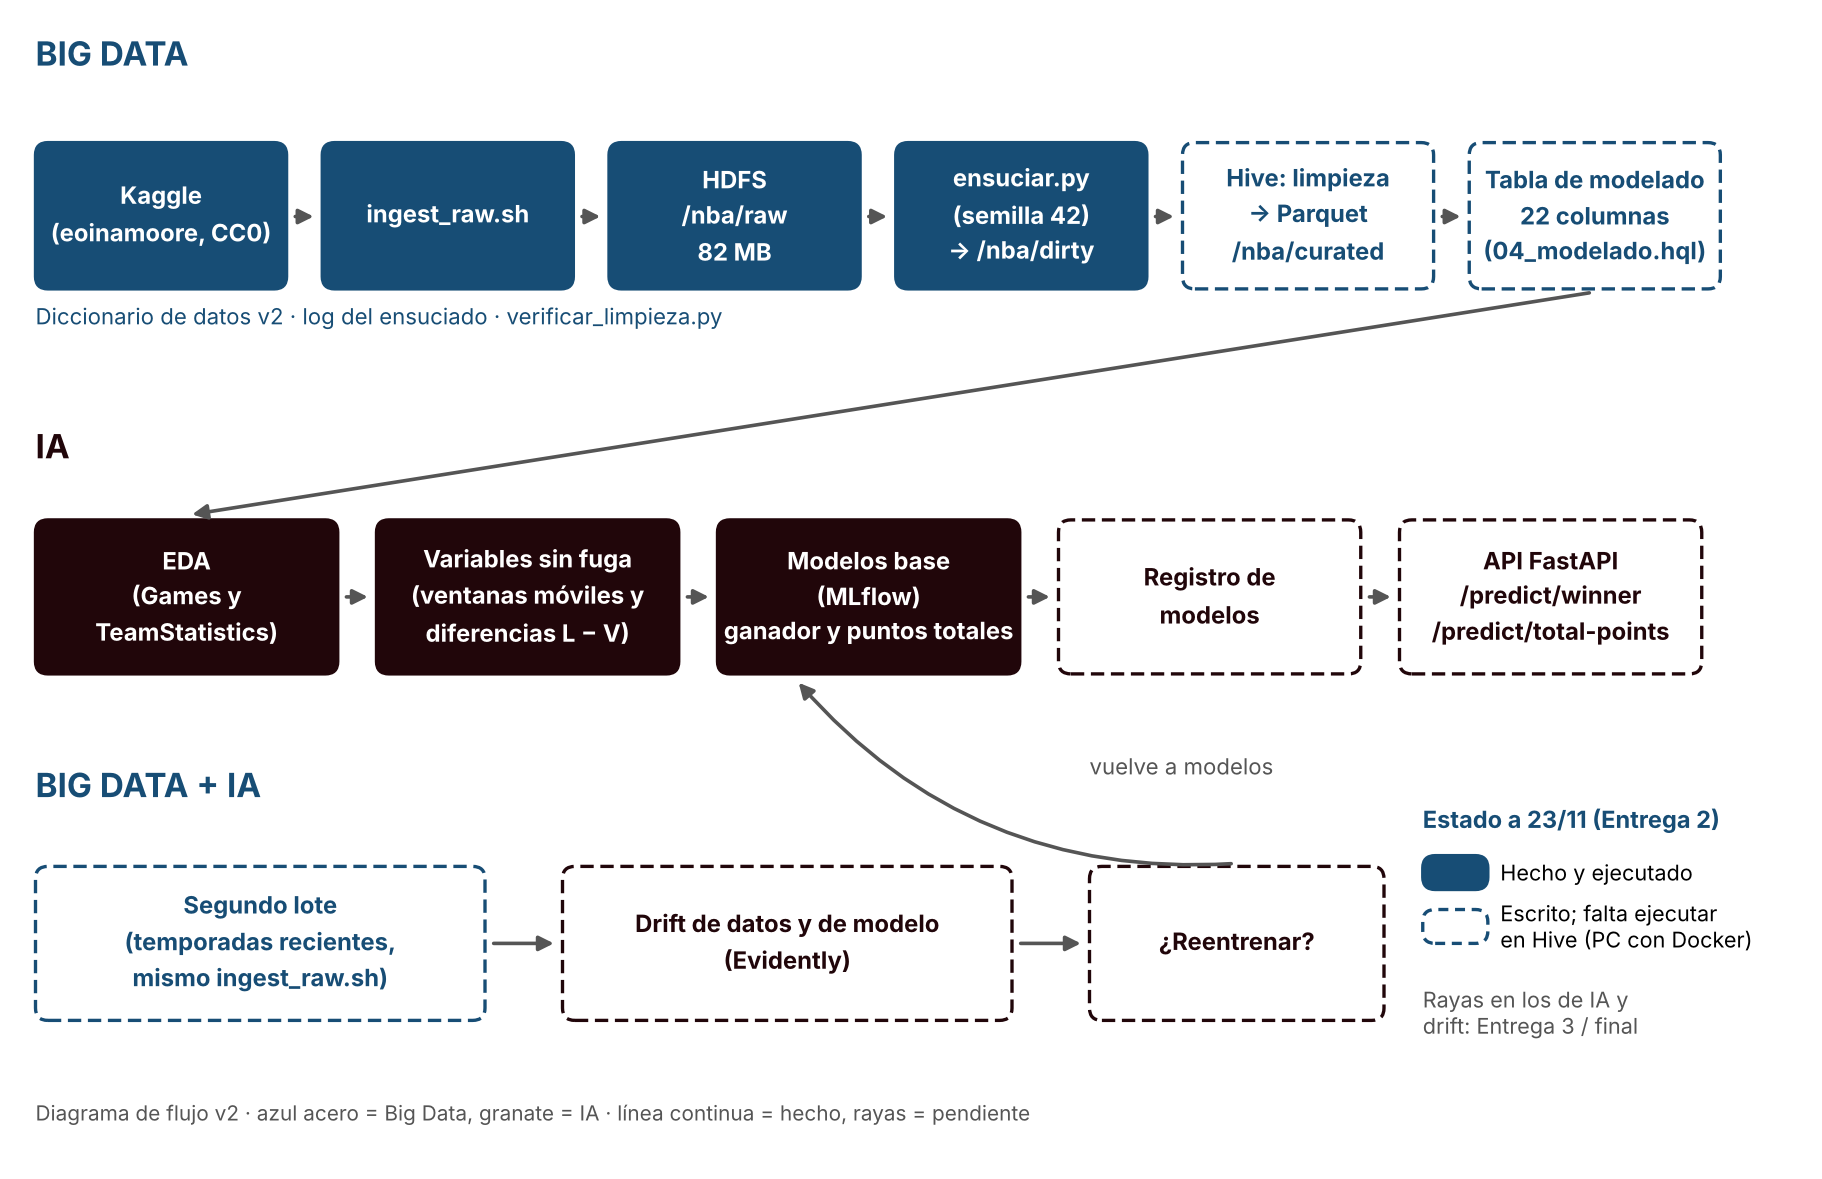

In [2]:
# El diagrama se hizo antes de ejecutar Hive: «Hive: limpieza» ya se ha ejecutado (ver sección 4).
display(Image(filename=str(RAIZ / "docs" / "img" / "HoopMind_diagrama_flujo_v2.png"), width=900))

> **En cristiano:** arriba (azul) está el trabajo de datos; en el medio (granate) la inteligencia artificial; abajo lo que une las dos cosas (cuando llegan datos nuevos, ¿el modelo sigue acertando?).
> Ese diagrama es de esta mañana: la caja «Hive: limpieza» aparece con rayas, pero **ya se ha ejecutado** (sección 4).

## 2. Los datos en HDFS: tres zonas

HDFS es el «disco duro» de Hadoop. Lo organizamos en zonas, de menos a más limpio:

| Zona | Ruta en HDFS | Qué contiene |
|---|---|---|
| **raw** | `/nba/raw/fecha=2026-11-17/` | Los CSV originales de Kaggle, **sin tocar** |
| **dirty** | `/nba/dirty/` | Los mismos datos **ensuciados** a propósito (con un registro de cada cambio) |
| **curated** | `/nba/curated/` | Datos limpios, con tipos correctos, en **Parquet** particionado por temporada |

Esto es lo que hay realmente en HDFS (salida de `hdfs dfs -ls` y `hdfs dfs -du -h` guardada en `logs/`):

In [3]:
for nombre in ("00_raw_ls.log", "03_hdfs_dirty_du.log"):
    print(f"--- {nombre}")
    print(ev(nombre).read_text(encoding="utf-8", errors="replace").strip(), "\n")

--- 00_raw_ls.log
Found 3 items
-rw-r--r--   1 root supergroup   11271951 2026-11-23 08:26 /nba/raw/fecha=2026-11-17/Games.csv
-rw-r--r--   1 root supergroup   36160696 2026-11-23 08:29 /nba/raw/fecha=2026-11-17/TeamStatistics.csv
-rw-r--r--   1 root supergroup   38491435 2026-11-23 08:26 /nba/raw/fecha=2026-11-17/TeamStatisticsExtended.csv 

--- 03_hdfs_dirty_du.log
10.7 M  10.7 M  /nba/dirty/games
7.4 M   7.4 M   /nba/dirty/log
34.6 M  34.6 M  /nba/dirty/team_statistics
36.7 M  36.7 M  /nba/staging/team_statistics_ext 



> **En cristiano:** los tres ficheros de `raw` (≈ 86 MB en total, más que los 2 MB que pide el enunciado) están subidos a Hadoop. `Games.csv` tiene un partido por fila; `TeamStatistics.csv` tiene dos filas por partido (una por equipo).
> `/nba/dirty` ocupa 10,7 + 34,6 MB, y su carpeta `log` (7,4 MB) guarda el registro de todo lo que ensuciamos.

## 3. El ensuciado: dato real = dato sucio

El enunciado pide trabajar con datos con problemas. Como los de Kaggle vienen bastante limpios, los **ensuciamos nosotros con `ensuciar.py`** (con una **semilla = 42**, así sale siempre lo mismo) y después la limpieza tiene que **recuperar el original**.
Ensuciamos ocho tipos de problema. Esta tabla sale directamente de `ensuciado_resumen.json`:

In [4]:
resumen = json.loads((SUCIO / "ensuciado_resumen.json").read_text(encoding="utf-8"))
DESC = {
    "1_nulos": "Celdas vacías en estadísticas",
    "2_duplicados": "Filas repetidas",
    "3_nombres": "Nombres de equipo mal escritos (Hwaks)",
    "4_fechas": "Fechas en otro formato (03/02/1955)",
    "5_imposibles": "Valores imposibles (415 puntos)",
    "6_tipos": "Texto donde va un número («108 pts»)",
    "7_intercambio": "Local y visitante cambiados (celdas)",
    "8_marcador": "Marcador distinto al real",
}
filas = []
for clave, n in resumen["cambios"].items():
    tabla, prob = clave.split("/")
    filas.append({"tabla": tabla, "problema": prob, "qué se hace": DESC[prob], "celdas cambiadas": n})
tab = pd.DataFrame(filas)
display(tab.style.hide(axis="index").format({"celdas cambiadas": "{:,}"}))
print(f"Total: {tab['celdas cambiadas'].sum():,} celdas cambiadas | semilla {resumen['semilla']}")
print("Filas Games:", f"{resumen['filas_originales']['games']:,} -> {resumen['filas_ensuciadas']['games']:,}",
      "| TeamStatistics:", f"{resumen['filas_originales']['team_statistics']:,} -> {resumen['filas_ensuciadas']['team_statistics']:,}")
print("Columnas quitadas por privacidad:", resumen["columnas_quitadas_minimizacion"])

tabla,problema,qué se hace,celdas cambiadas
games,2_duplicados,Filas repetidas,735
games,3_nombres,Nombres de equipo mal escritos (Hwaks),"1,425"
games,4_fechas,Fechas en otro formato (03/02/1955),"3,677"
games,6_tipos,Texto donde va un número («108 pts»),"7,315"
games,7_intercambio,Local y visitante cambiados (celdas),"1,766"
games,8_marcador,Marcador distinto al real,368
team_statistics,1_nulos,Celdas vacías en estadísticas,"75,024"
team_statistics,2_duplicados,Filas repetidas,"1,471"
team_statistics,3_nombres,Nombres de equipo mal escritos (Hwaks),"2,868"
team_statistics,4_fechas,Fechas en otro formato (03/02/1955),"7,355"


Total: 117,126 celdas cambiadas | semilla 42
Filas Games: 73,544 -> 74,279 | TeamStatistics: 147,106 -> 148,577
Columnas quitadas por privacidad: {'games': ['officials'], 'team_statistics': ['coachId']}


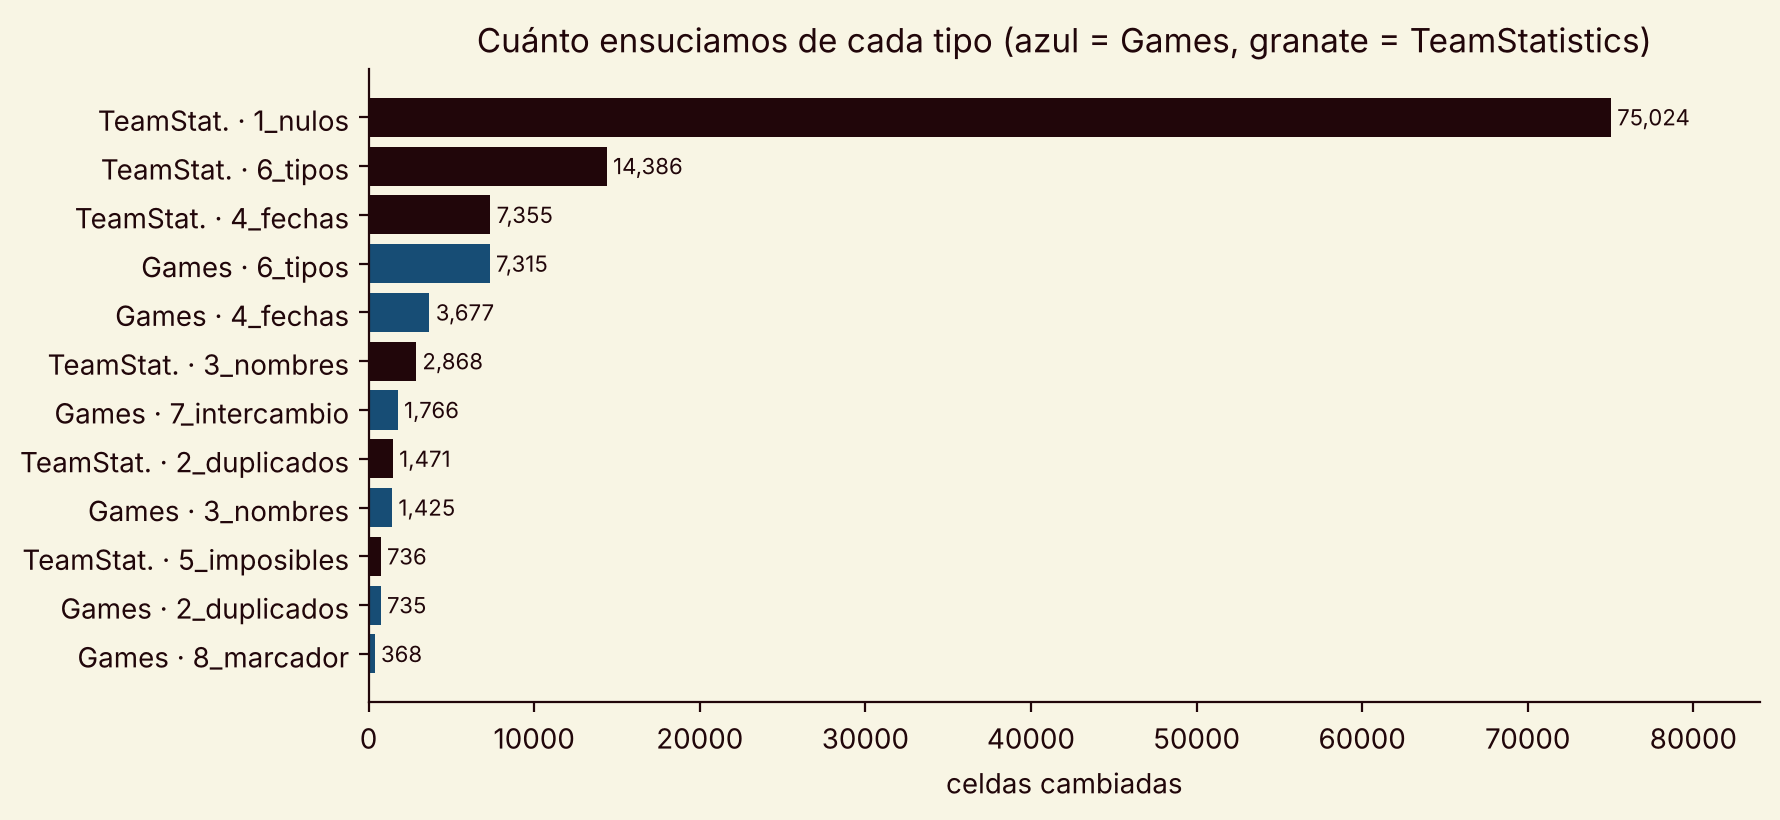

In [5]:
et = tab.assign(etq=tab.tabla.str.replace("team_statistics", "TeamStat.").str.replace("games", "Games") + " · " + tab.problema)
et = et.sort_values("celdas cambiadas")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(et.etq, et["celdas cambiadas"], color=[AZUL if t == "games" else GRANATE for t in et.tabla])
for y, v in enumerate(et["celdas cambiadas"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("celdas cambiadas"); ax.set_title("Cuánto ensuciamos de cada tipo (azul = Games, granate = TeamStatistics)")
ax.set_xlim(0, et["celdas cambiadas"].max() * 1.12)
plt.tight_layout(); plt.show()

Un ejemplo real de cada tipo, tomado del registro `ensuciado_log.csv` (una fila por celda cambiada, con el valor original y el nuevo):

In [6]:
reg = pd.read_csv(SUCIO / "ensuciado_log.csv", dtype=str, keep_default_na=False)
ej = reg[reg.valor_original != ""].sample(frac=1, random_state=3).groupby(["tabla", "problema"]).head(1).sort_values(["tabla", "problema"])
display(ej[["tabla", "problema", "gameId", "columna", "valor_original", "valor_nuevo"]].reset_index(drop=True))

,tabla,problema,gameId,columna,valor_original,valor_nuevo
0,games,3_nombres,22100671,hometeamName,Celtics,celtics
1,games,4_fechas,21000945,gameDateTimeEst,2011-03-07 20:00:00,2011/03/07 20:00:00
2,games,6_tipos,27500304,homeScore,89,89 pts
3,games,7_intercambio,26600196,hometeamId,1610612755,1610612752
4,games,8_marcador,25700192,awayScore,104,96
5,team_statistics,1_nulos,27900744,threePointersPercentage,0.0,
6,team_statistics,3_nombres,28400872,teamName,Nets,NETS
7,team_statistics,4_fechas,27200056,gameDateTimeEst,1972-10-27 19:00:00,10-27-1972 19:00:00
8,team_statistics,5_imposibles,22600178,threePointersPercentage,0.273,2.198
9,team_statistics,6_tipos,42400114,steals,5,5.0


> **En cristiano:** el mayor volumen son los **nulos** (75 024 celdas vacías en TeamStatistics) y los **tipos erróneos** (≈ 21 700 celdas con texto en lugar de número). Lo más delicado son los 1 766 cambios de local/visitante y los 368 marcadores alterados: pueden **dar la vuelta al resultado** de un partido y estropear el objetivo 1 si no se corrigen.
> Como guardamos el valor original de cada celda, podemos **medir exactamente** cuánto recupera la limpieza.

## 4. La limpieza con Hive → Parquet

`hive/02_limpieza_curated.hql` hace la limpieza con reglas (no a mano): quita duplicados (`ROW_NUMBER`), lee las fechas en 5 formatos, quita «pts» de los números, pone el nombre de equipo más frecuente de cada temporada, **contrasta Games con TeamStatistics** para detectar local/visitante invertidos y marcadores mal, y recalcula valores a partir de otros (p. ej. porcentaje de tiro = anotados / intentados).
El resultado se escribe en `/nba/curated/` como **Parquet + Snappy, particionado por temporada**.

Lo que dijo Hive al ejecutar las comprobaciones (`hive/03_comprobaciones.hql`) en el PC de Aimar, leído de `logs/06_comprobaciones_hive.log`:

In [7]:
texto = ev("06_comprobaciones_hive.log").read_text(encoding="utf-8", errors="replace")
bloques, actual = [], []
for l in texto.splitlines():
    if l.startswith("|"):
        actual.append([c.strip() for c in l.strip().strip("|").split("|")])
    elif actual and not l.startswith("+"):
        bloques.append(actual); actual = []
if actual: bloques.append(actual)
tablas = []
for b in bloques:
    cab = [c.split(".")[-1] for c in b[0]]
    tablas.append(pd.DataFrame(b[1:], columns=cab))
for t in tablas:
    display(t.style.hide(axis="index"))

paso,filas
1 games / dirty,74279
2 games / sin duplicados,73544
3 games / curated.partidos,73546
4 team_statistics / dirty,148577
5 team_statistics / sin duplicados,147106
6 team_statistics / curated.estadisticas_equipo,147028
7 team_statistics_ext / raw,80342
8 team_statistics_ext / curated.estadisticas_avanzadas,80260


tabla,claves_repetidas
estadisticas_equipo,0
partidos,2


tabla,sin_fecha
team_statistics,78
games,0


partidos,no_coinciden
73546,164


local_visitante_corregidos,marcadores_corregidos,ganador_incoherente,jugados,sin_jugar
221,370,0,73542,4


filas_con_valores_fuera_de_rango,puntos_recalculados,puntos_distintos_de_suma_de_cuartos,datos_recuperados_con_reglas,huecos_antes_de_imputar
752,356,207,45361,30075


In [8]:
filas = tablas[0].set_index("paso")["filas"].astype(int)
ori_g, ori_t = resumen["filas_originales"]["games"], resumen["filas_originales"]["team_statistics"]
n = filas.to_dict()
g_dirty, g_sin, g_cur = n["1 games / dirty"], n["2 games / sin duplicados"], n["3 games / curated.partidos"]
t_dirty, t_sin, t_cur = n["4 team_statistics / dirty"], n["5 team_statistics / sin duplicados"], n["6 team_statistics / curated.estadisticas_equipo"]
res = pd.DataFrame([
    ["Games", ori_g, g_dirty, g_sin, g_cur, resumen["cambios"]["games/2_duplicados"]],
    ["TeamStatistics", ori_t, t_dirty, t_sin, t_cur, resumen["cambios"]["team_statistics/2_duplicados"]]],
    columns=["tabla", "filas originales", "filas sucias", "tras quitar duplicados", "filas en curated", "duplicados metidos"])
res["duplicados quitados"] = res["filas sucias"] - res["tras quitar duplicados"]
display(res.style.hide(axis="index").format({c: "{:,}" for c in res.columns[1:]}))

tabla,filas originales,filas sucias,tras quitar duplicados,filas en curated,duplicados metidos,duplicados quitados
Games,"73,544","74,279","73,544","73,546",735,735
TeamStatistics,"147,106","148,577","147,106","147,028","1,471","1,471"


Lectura de los números (todos salen de los logs):

- **Duplicados:** metimos 735 (Games) y 1 471 (TeamStatistics); Hive quitó **exactamente 735 y 1 471**. ✔
- **Local/visitante:** Hive corrigió **221 partidos** (metimos 1 766 celdas cambiadas, unas 8 por partido ≈ 221 partidos). ✔
- **Marcadores:** corrigió **370** (metimos 368 celdas). Los 2 de más pueden ser incoherencias que ya traía el dato original; **hay que mirarlo**.
- **Ganador incoherente:** 0. Ningún partido tiene un `winner` que contradiga el marcador. ✔
- **Valores imposibles:** 752 filas fuera de rango detectadas (metimos 736 filas con valores imposibles).
- **Huecos:** Hive rellenó **45 361 datos con reglas** (p. ej. anotados / intentados); quedaron **30 075 huecos** que se imputan con una media móvil (ahí no se espera el 100 %).

⚠️ **Cosas que no cuadran del todo y apuntamos como pendientes** (ver sección 8): `curated.partidos` tiene **2 filas más** que el original (2 claves repetidas) y se pierden **78 filas de TeamStatistics** porque su fecha no se pudo leer.

> **En cristiano:** la limpieza hace casi todo lo esperado y los contadores de Hive coinciden con lo que ensuciamos. Lo que **todavía no tenemos** es la medida más importante: «de todas las celdas que ensuciamos, ¿cuántas han vuelto a su valor original?». Eso lo calcula `verificar_limpieza.py` y necesita la exportación de curated a CSV (siguiente celda).

### 4.1 Recuperación medida (`verificar_limpieza.py`)

Compara tres cosas: el **original (raw)**, el **registro del ensuciado** y el **curated**. Para cada celda que ensuciamos mira si el valor curado es igual al original.
También cuenta los **daños colaterales** (celdas que no ensuciamos y que la limpieza ha cambiado; lo ideal es 0).

In [9]:
verif = RAIZ / "scripts" / "verificar_limpieza.py"
hay_curado = (CURADO / "partidos.csv").exists() and (CURADO / "estadisticas_equipo.csv").exists()
if hay_curado:
    import subprocess, sys
    r = subprocess.run([sys.executable, str(verif), "--raw", str(RAW), "--log", str(SUCIO / "ensuciado_log.csv"),
                        "--curated", str(CURADO), "--informe", str(LOGS / "verificacion_limpieza.csv")],
                       capture_output=True, text=True)
    print(r.stdout[-6000:] or r.stderr[-3000:])
else:
    display(Markdown("**⏳ PENDIENTE.** Todavía no existe `data/curated_export/` (la exportación de Parquet a CSV, paso 7 de `pipeline_limpieza.sh`). "
                     "Cuando termine esa ejecución en el PC de Aimar, esta misma celda calcula el **porcentaje de recuperación por problema** y los daños colaterales, sin tocar nada más."))

**⏳ PENDIENTE.** Todavía no existe `data/curated_export/` (la exportación de Parquet a CSV, paso 7 de `pipeline_limpieza.sh`). Cuando termine esa ejecución en el PC de Aimar, esta misma celda calcula el **porcentaje de recuperación por problema** y los daños colaterales, sin tocar nada más.

## 5. Reducción de columnas: de 55 a 22

La primera tabla de modelado tenía **55 columnas** (5 de identificación + **48 entradas** + 2 salidas). Eran demasiadas y muy parecidas entre sí. En vez de quitar columnas «a ojo», **probamos variantes** con los mismos modelos y el mismo trozo de prueba (temporada 2023-24), con `comparar_columnas.py`:

variante,n_entradas,auc_logistica,auc_boosting,mae_ridge,mae_boosting
A todas 48,48,0.711,0.706,14.78,14.91
B sin ventana5,40,0.712,0.709,14.79,15.00
C B sin back2back ni victorias,36,0.704,0.703,14.77,15.02
D solo diferencias sin sumas,13,0.704,0.703,26.40,25.75
E FINAL diferencias y sumas,15,0.704,0.700,14.83,14.93


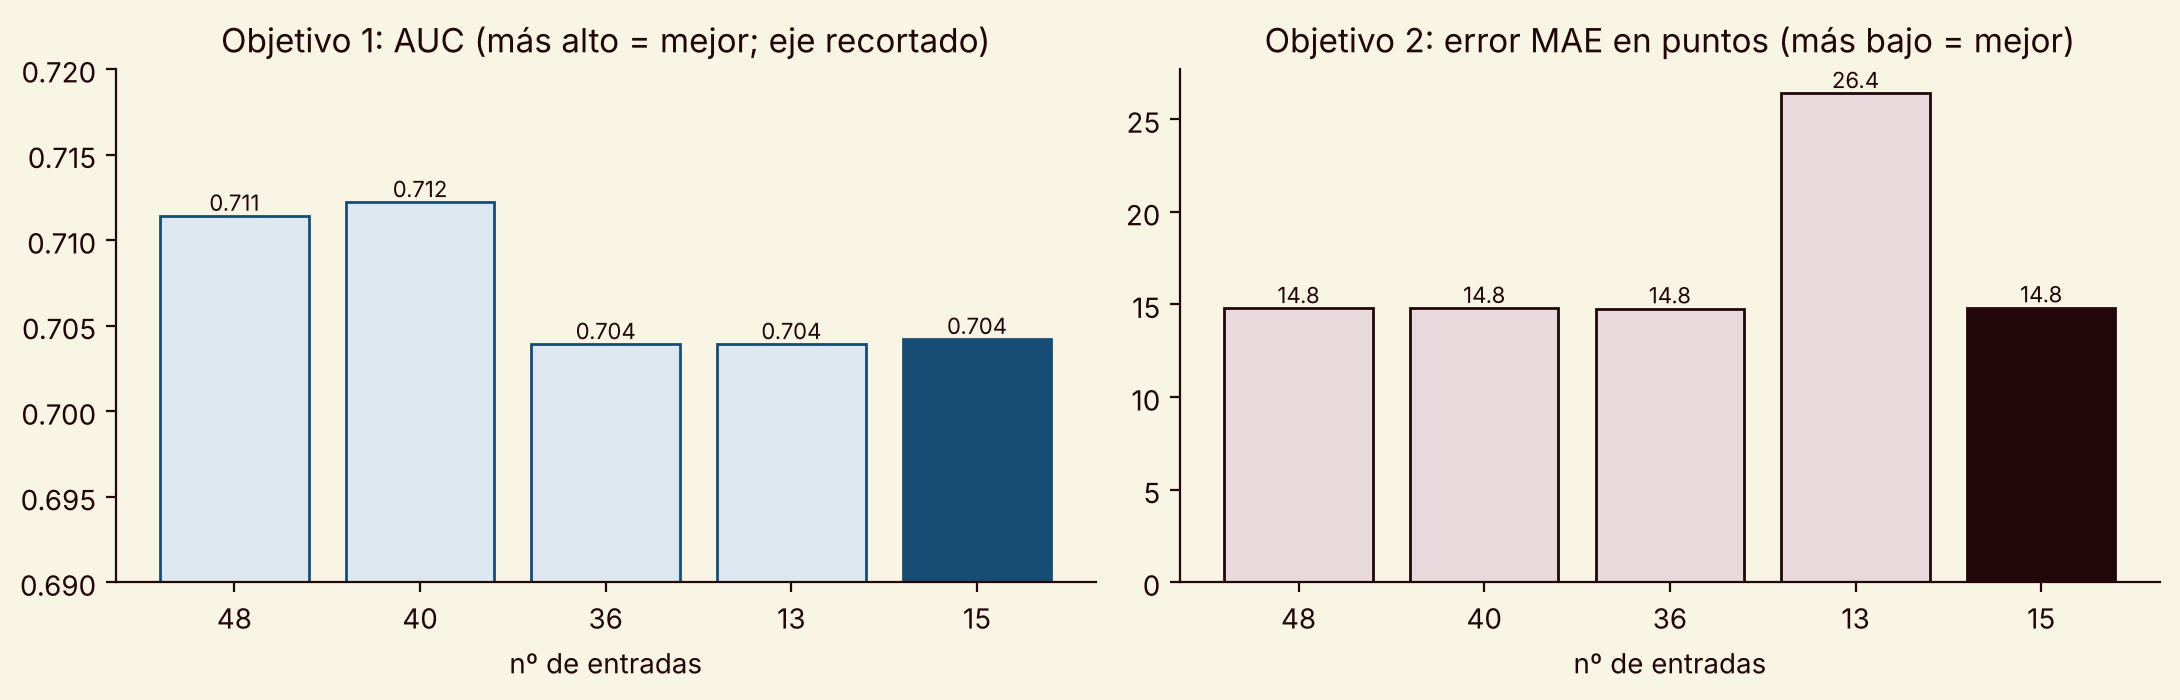

In [10]:
sel = pd.read_csv(RAIZ / "docs" / "seleccion_columnas_resultados.csv")
sel["variante"] = sel["variante"].str.replace("_", " ")
display(sel.style.hide(axis="index").format({"auc_logistica": "{:.3f}", "auc_boosting": "{:.3f}", "mae_ridge": "{:.2f}", "mae_boosting": "{:.2f}"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
col = [AZUL_CLARO] * 4 + [AZUL]
ax[0].bar(sel.n_entradas.astype(str), sel.auc_logistica, color=col, edgecolor=AZUL)
ax[0].set_ylim(0.69, 0.72); ax[0].set_title("Objetivo 1: AUC (más alto = mejor; eje recortado)"); ax[0].set_xlabel("nº de entradas")
ax[1].bar(sel.n_entradas.astype(str), sel.mae_ridge, color=[GRANATE_CLARO] * 3 + [GRANATE_CLARO, GRANATE], edgecolor=GRANATE)
ax[1].set_title("Objetivo 2: error MAE en puntos (más bajo = mejor)"); ax[1].set_xlabel("nº de entradas")
for a in ax:
    for p in a.patches:
        a.text(p.get_x() + p.get_width() / 2, p.get_height(), f"{p.get_height():.3f}" if a is ax[0] else f"{p.get_height():.1f}",
               ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**La tabla final tiene 22 columnas** = 5 de identificación + **15 entradas** + 2 salidas. Las 15 entradas son:
- **13 diferencias local − visitante** de cómo llegaba cada equipo (media de sus **últimos 10 partidos**: puntos a favor y en contra, % de victorias, % de tiro, triples, tiros libres, rebotes, asistencias, pérdidas, robos, tapones) + días de descanso + % de victorias de la temporada;
- **2 sumas** de puntos a favor y en contra de los dos equipos (clave para predecir los puntos totales).

> **En cristiano:** pasar de 48 a 15 entradas casi no cambia el acierto (AUC 0,711 → 0,704; MAE 14,8 → 14,8) pero el modelo es **más simple, rápido y fácil de explicar**. Las diferencias «local − visitante» sirven para el ganador; **las sumas son imprescindibles para los puntos**: sin ellas (variante de 13) el error sube de 14,8 a 26,4 puntos.
> **Regla anti-trampa (sin fuga de datos):** cada entrada se calcula solo con partidos **anteriores** al que se predice (`shift(1)` y después la media): el partido de hoy nunca entra en su propio resumen.

## 6. Exploración de los datos (EDA)

Construimos la tabla de modelado con las funciones reales del repo (`scripts/construir_modelado.py`) y miramos cómo se comportan las salidas.
⚠️ **Nota honesta:** de momento se construye con los CSV **originales** (la limpieza de Hive aún no está exportada); cuando lo esté, el mismo código se lanza con `--curated` y debería dar casi lo mismo.

In [11]:
spec = importlib.util.spec_from_file_location("construir_modelado", RAIZ / "scripts" / "construir_modelado.py")
cm = importlib.util.module_from_spec(spec); spec.loader.exec_module(cm)
g, e = cm.cargar_raw(RAW)
ds = cm.construir(g, e)
X = cm.ENTRADAS; SAL = cm.SALIDAS
print(f"Tabla de modelado: {len(ds):,} partidos x {ds.shape[1]} columnas ({len(cm.IDENT)} identificación + {len(X)} entradas + {len(SAL)} salidas)")
print("Temporadas:", int(ds.temporada.min()), "a", int(ds.temporada.max()))
display(ds.head(4).round(3))

Tabla de modelado: 31,218 partidos x 22 columnas (5 identificación + 15 entradas + 2 salidas)
Temporadas: 2000 a 2026


,game_id,game_date,temporada,home_team_id,away_team_id,dif_pts_favor_ult10,dif_pts_contra_ult10,dif_win_pct_ult10,dif_tiro_campo_pct_ult10,dif_triples_pct_ult10,dif_libres_pct_ult10,dif_rebotes_ult10,dif_asistencias_ult10,dif_perdidas_ult10,dif_robos_ult10,dif_tapones_ult10,dif_dias_descanso,dif_win_pct_temporada,suma_pts_favor_ult10,suma_pts_contra_ult10,home_win,puntos_totales
0,20000142,2000-11-18,2000,1610612746,1610612760,-7.0,-6.4,0.1,-0.012,-0.068,-0.084,1.0,-3.8,-2.4,-2.6,0.3,1.0,0.100,182.2,190.0,0,169
1,20000145,2000-11-19,2000,1610612753,1610612757,-0.2,7.5,-0.2,-0.064,-0.058,-0.050,-0.9,-4.2,1.7,2.7,-1.3,2.0,-0.145,185.0,185.7,0,212
2,20000146,2000-11-19,2000,1610612765,1610612766,6.3,7.4,0.0,0.015,-0.010,0.055,3.5,1.3,2.6,0.1,-0.5,0.0,0.000,181.5,184.4,0,201
3,20000153,2000-11-21,2000,1610612764,1610612757,-5.3,3.6,-0.4,-0.037,0.007,-0.031,-3.0,-3.6,0.3,-0.8,-1.2,1.0,-0.311,185.5,180.6,0,198


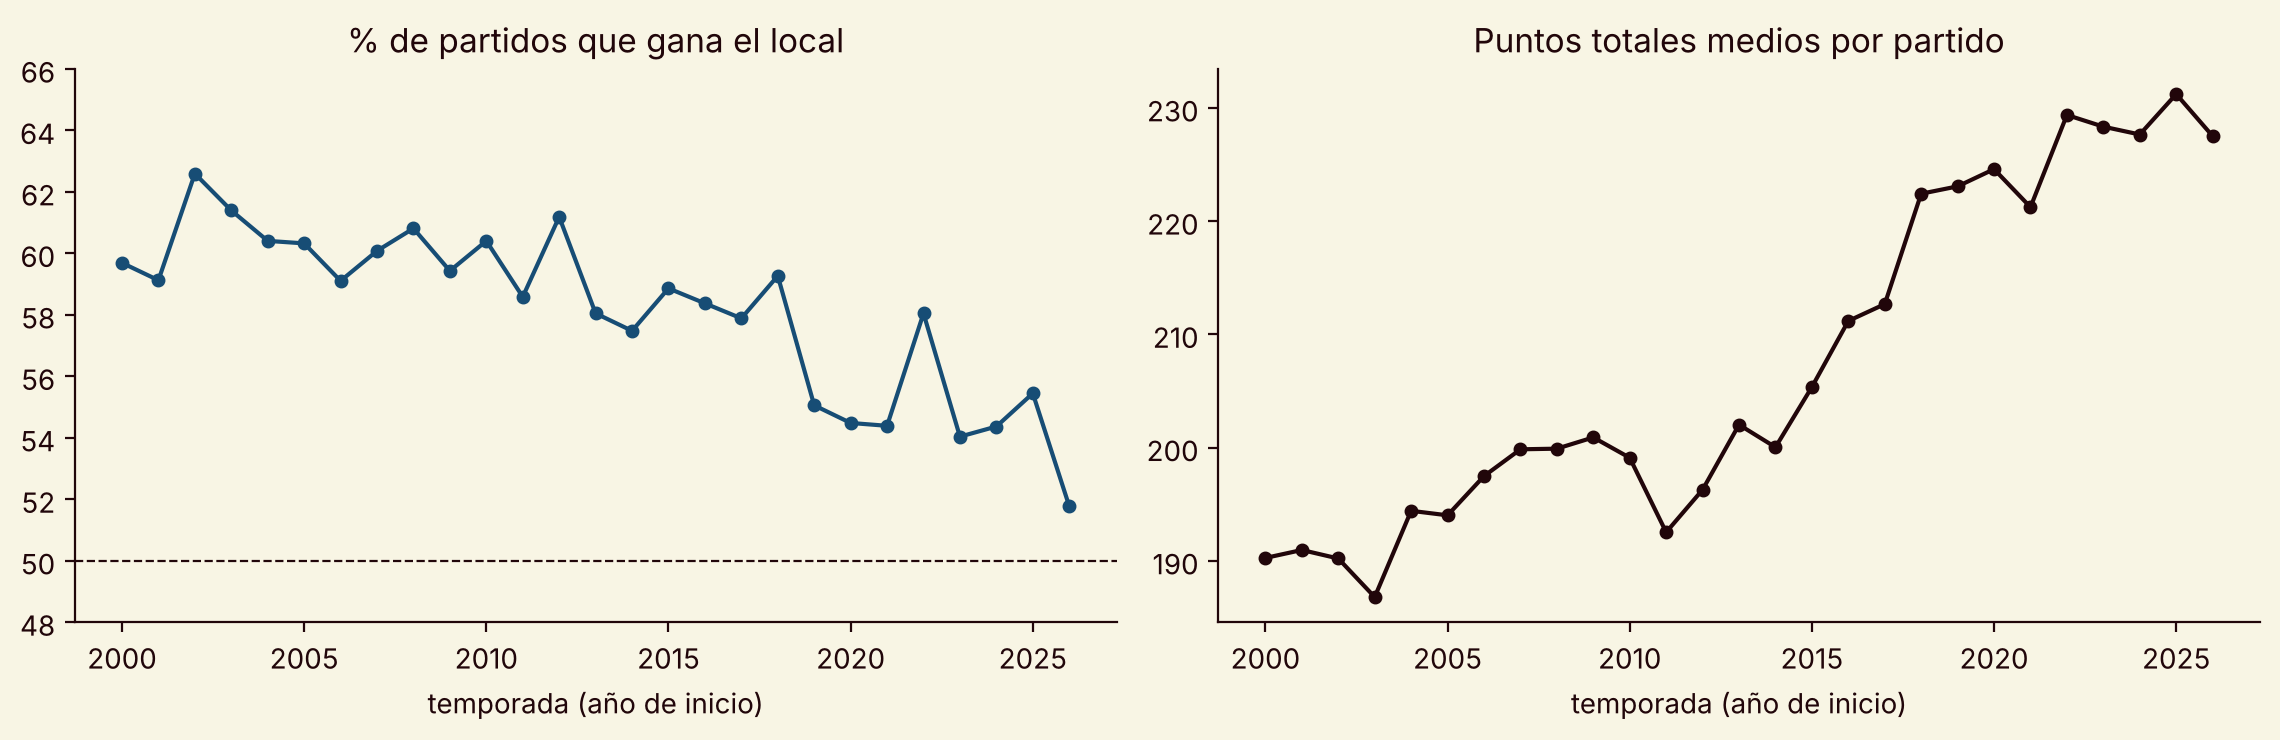

Ganar en casa: 59.7 % en 2000 -> 51.8 % en 2026
Puntos totales medios: 190 en 2000 -> 228 en 2026


In [12]:
por_t = ds.groupby("temporada").agg(partidos=("game_id", "size"), pct_local=("home_win", "mean"), puntos=("puntos_totales", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].plot(por_t.index, por_t.pct_local * 100, color=AZUL, marker="o", ms=4)
ax[0].axhline(50, color=GRANATE, lw=.8, ls="--"); ax[0].set_ylim(48, 66)
ax[0].set_title("% de partidos que gana el local"); ax[0].set_xlabel("temporada (año de inicio)")
ax[1].plot(por_t.index, por_t.puntos, color=GRANATE, marker="o", ms=4)
ax[1].set_title("Puntos totales medios por partido"); ax[1].set_xlabel("temporada (año de inicio)")
plt.tight_layout(); plt.show()
print(f"Ganar en casa: {por_t.pct_local.iloc[0]*100:.1f} % en {por_t.index[0]} -> {por_t.pct_local.iloc[-1]*100:.1f} % en {por_t.index[-1]}")
print(f"Puntos totales medios: {por_t.puntos.iloc[0]:.0f} en {por_t.index[0]} -> {por_t.puntos.iloc[-1]:.0f} en {por_t.index[-1]}")

> **En cristiano:** (izquierda) la ventaja de jugar en casa **baja con los años** (≈ 60 % en 2000 → 52-55 % en las últimas temporadas). (derecha) **se anotan muchos más puntos**: de ≈ 190 por partido en 2000 a ≈ 230 hoy. Esto es importante: un modelo entrenado con partidos antiguos va a **quedarse corto** al predecir puntos de partidos recientes (lo medimos en la sección 7).

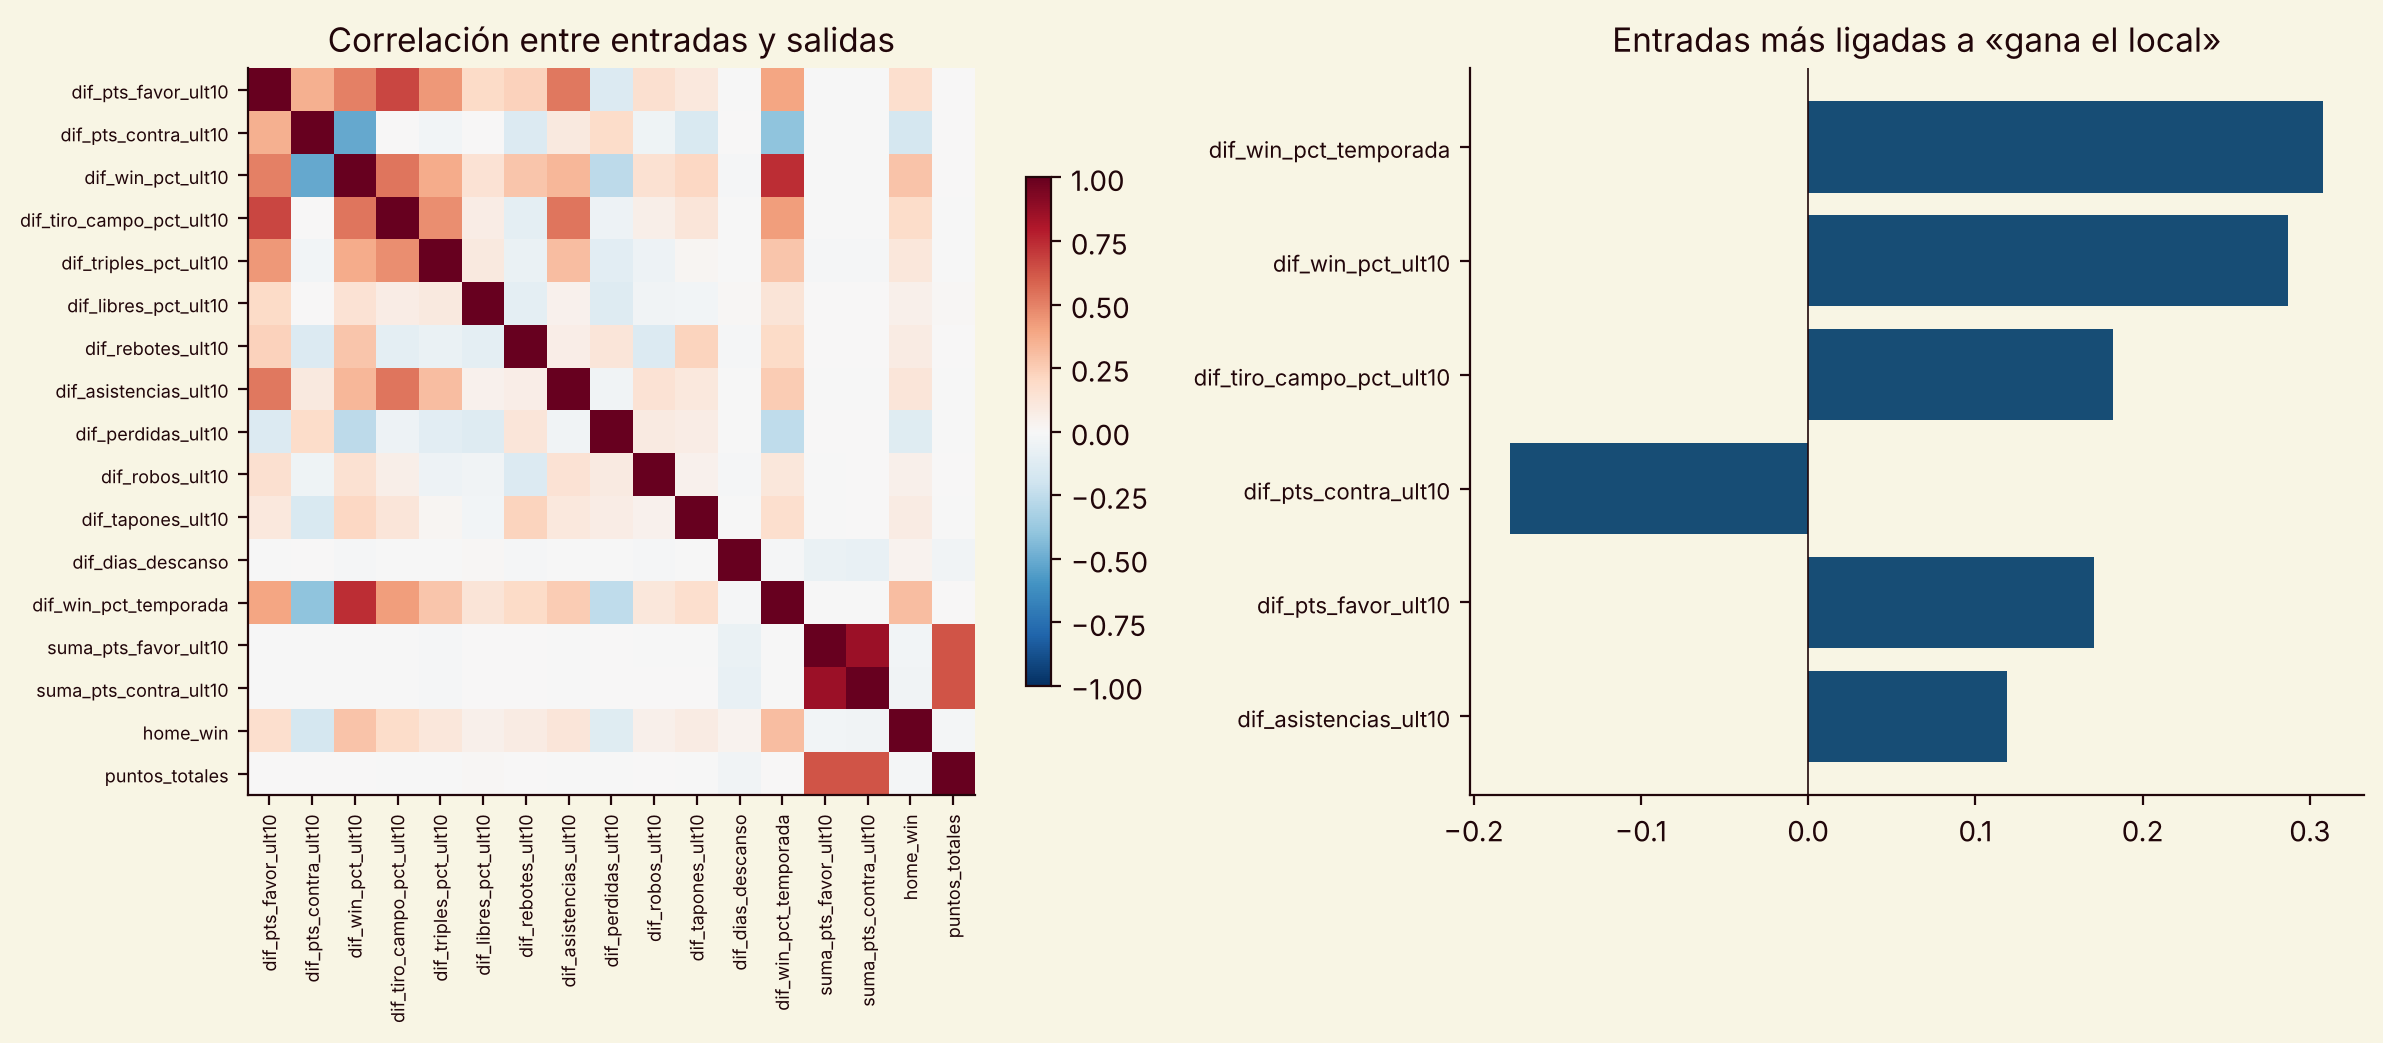

Mayor correlación con puntos_totales: {'suma_pts_favor_ult10': 0.629, 'suma_pts_contra_ult10': 0.627}


In [13]:
corr = ds[X + SAL].corr()
c_out = corr.loc[X, SAL].round(3)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(corr))); ax[0].set_xticklabels(corr.columns, rotation=90, fontsize=6.5)
ax[0].set_yticks(range(len(corr))); ax[0].set_yticklabels(corr.columns, fontsize=6.5)
ax[0].set_title("Correlación entre entradas y salidas"); plt.colorbar(im, ax=ax[0], shrink=.7)
top = c_out.home_win.abs().sort_values().tail(6).index
ax[1].barh(top, c_out.loc[top, "home_win"], color=AZUL)
ax[1].set_title("Entradas más ligadas a «gana el local»"); ax[1].axvline(0, color=GRANATE, lw=.6)
ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print("Mayor correlación con puntos_totales:", c_out.puntos_totales.abs().sort_values(ascending=False).head(2).round(3).to_dict())

> **En cristiano:** la correlación mide si dos cosas suben juntas (1 = siempre, 0 = nada). Para saber **quién gana**, lo que más pesa es el **% de victorias** (de la temporada y de los últimos 10) y los puntos que anota/recibe cada equipo. Para los **puntos totales**, casi todo lo explican las dos **sumas** de puntos (correlación ≈ 0,63).
> Ninguna correlación individual es altísima: el baloncesto tiene mucho azar y por eso **no esperamos un 90 % de acierto**.

## 7. Modelos base y deriva (drift)

**Cortes por fecha** (no se mezclan filas al azar, para no «ver el futuro»):

| Trozo | Temporadas | Para qué |
|---|---|---|
| **Entrenamiento** | hasta 2022-23 | Aprender |
| **Prueba** | 2023-24 | Medir cómo acierta con partidos que no ha visto |
| **Segundo lote (drift)** | 2024-25 y 2025-26 (en curso) | Medir cuánto **empeora** con datos más recientes |

Modelos: una **referencia tonta** (baseline), un modelo **simple** (regresión logística / Ridge) y uno **más potente** (boosting). Son los mismos de `scripts/modelos_base.py` (que además los registra en MLflow).

In [14]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier as HGBC, HistGradientBoostingRegressor as HGBR
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, log_loss, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tr, te, l2 = ds.temporada <= 2022, ds.temporada == 2023, ds.temporada > 2023
print(f"entrenamiento {tr.sum():,} partidos | prueba {te.sum():,} | segundo lote {l2.sum():,}")
pre = lambda m: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), m)

# ---- Objetivo 1: ¿gana el local? ----
y = ds.home_win
m1 = {"Gana siempre el local (baseline)": DummyClassifier(strategy="constant", constant=1),
      "Regresión logística": pre(LogisticRegression(max_iter=2000)),
      "Boosting": HGBC(max_iter=200, learning_rate=.05, random_state=0)}
r1 = []
for nombre, m in m1.items():
    m.fit(ds.loc[tr, X], y[tr])
    fila = {"modelo": nombre}
    for tag, mask in [("prueba", te), ("lote2", l2)]:
        p = m.predict_proba(ds.loc[mask, X])[:, 1] if "baseline" not in nombre else np.full(mask.sum(), y[tr].mean())
        fila[f"acierto_{tag}"] = accuracy_score(y[mask], m.predict(ds.loc[mask, X]))
        fila[f"auc_{tag}"] = roc_auc_score(y[mask], p) if "baseline" not in nombre else 0.5
        fila[f"probmedia_{tag}"] = p.mean()
    r1.append(fila)
r1 = pd.DataFrame(r1)
display(r1.style.hide(axis="index").format({c: "{:.3f}" for c in r1.columns[1:]}))

entrenamiento 27,402 partidos | prueba 1,164 | segundo lote 2,652


modelo,acierto_prueba,auc_prueba,probmedia_prueba,acierto_lote2,auc_lote2,probmedia_lote2
Gana siempre el local (baseline),0.540,0.500,0.589,0.547,0.500,0.589
Regresión logística,0.643,0.704,0.566,0.662,0.722,0.567
Boosting,0.639,0.700,0.566,0.660,0.717,0.564


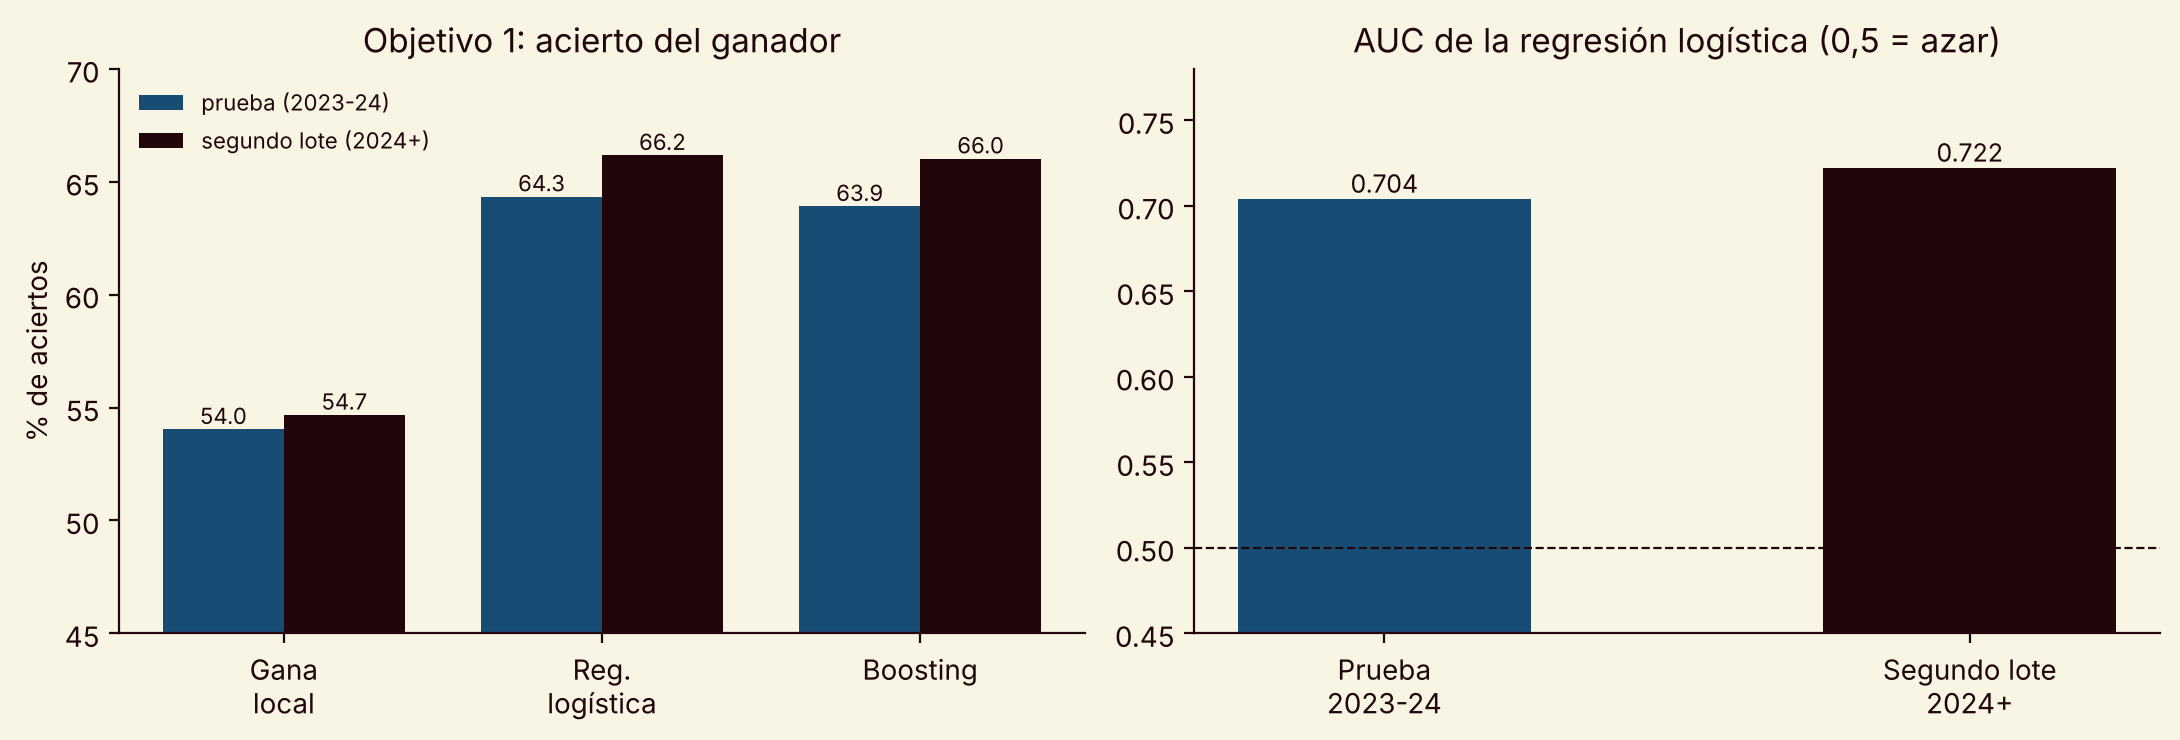

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(r1)); w = .38
ax[0].bar(x - w/2, r1.acierto_prueba * 100, w, color=AZUL, label="prueba (2023-24)")
ax[0].bar(x + w/2, r1.acierto_lote2 * 100, w, color=GRANATE, label="segundo lote (2024+)")
ax[0].set_xticks(x); ax[0].set_xticklabels(["Gana\nlocal", "Reg.\nlogística", "Boosting"])
ax[0].set_ylim(45, 70); ax[0].set_ylabel("% de aciertos"); ax[0].legend(frameon=False, fontsize=8, loc="upper left")
ax[0].set_title("Objetivo 1: acierto del ganador")
for p in ax[0].patches: ax[0].text(p.get_x() + p.get_width()/2, p.get_height(), f"{p.get_height():.1f}", ha="center", va="bottom", fontsize=8)
ax[1].bar(["Prueba\n2023-24", "Segundo lote\n2024+"], [r1.auc_prueba[1], r1.auc_lote2[1]], color=[AZUL, GRANATE], width=.5)
ax[1].axhline(.5, color=GRANATE, ls="--", lw=.8); ax[1].set_ylim(.45, .78); ax[1].set_title("AUC de la regresión logística (0,5 = azar)")
for p in ax[1].patches: ax[1].text(p.get_x() + p.get_width()/2, p.get_height(), f"{p.get_height():.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

> **En cristiano:** si predecimos siempre «gana el local» acertamos ≈ **54 %** de las veces en la prueba. La regresión logística acierta **≈ 64 %** con **AUC 0,704** (el AUC es la probabilidad de que el modelo ponga más alto a un partido que de verdad ganó el local que a uno que no; 0,5 es lanzar una moneda y 1 es perfecto). Es una mejora real, aunque modesta: el baloncesto tiene mucho azar. En el segundo lote el modelo **no empeora** (AUC 0,722, acierto 66 %): para el ganador no vemos deriva preocupante.
> El boosting (modelo más complejo) **no mejora** al simple, así que nos quedamos con el sencillo como referencia.

In [16]:
# ---- Objetivo 2: puntos totales ----
y = ds.puntos_totales
m2 = {"Siempre la media (baseline)": DummyRegressor(strategy="mean"),
      "Ridge": pre(Ridge(alpha=10)),
      "Boosting": HGBR(max_iter=200, learning_rate=.05, random_state=0)}
r2 = []
for nombre, m in m2.items():
    m.fit(ds.loc[tr, X], y[tr])
    fila = {"modelo": nombre}
    for tag, mask in [("prueba", te), ("lote2", l2)]:
        p = m.predict(ds.loc[mask, X])
        fila[f"mae_{tag}"] = mean_absolute_error(y[mask], p)
        fila[f"media_pred_{tag}"] = p.mean(); fila[f"media_real_{tag}"] = y[mask].mean()
    r2.append(fila)
r2 = pd.DataFrame(r2)
display(r2.style.hide(axis="index").format({c: "{:.2f}" for c in r2.columns[1:]}))
print(f"Puntos totales medios: entrenamiento {y[tr].mean():.0f}  ->  segundo lote {y[l2].mean():.0f}")

modelo,mae_prueba,media_pred_prueba,media_real_prueba,mae_lote2,media_pred_lote2,media_real_lote2
Siempre la media (baseline),26.47,203.71,228.34,27.24,203.71,229.29
Ridge,14.83,229.61,228.34,15.12,230.01,229.29
Boosting,14.93,227.35,228.34,15.32,227.72,229.29


Puntos totales medios: entrenamiento 204  ->  segundo lote 229


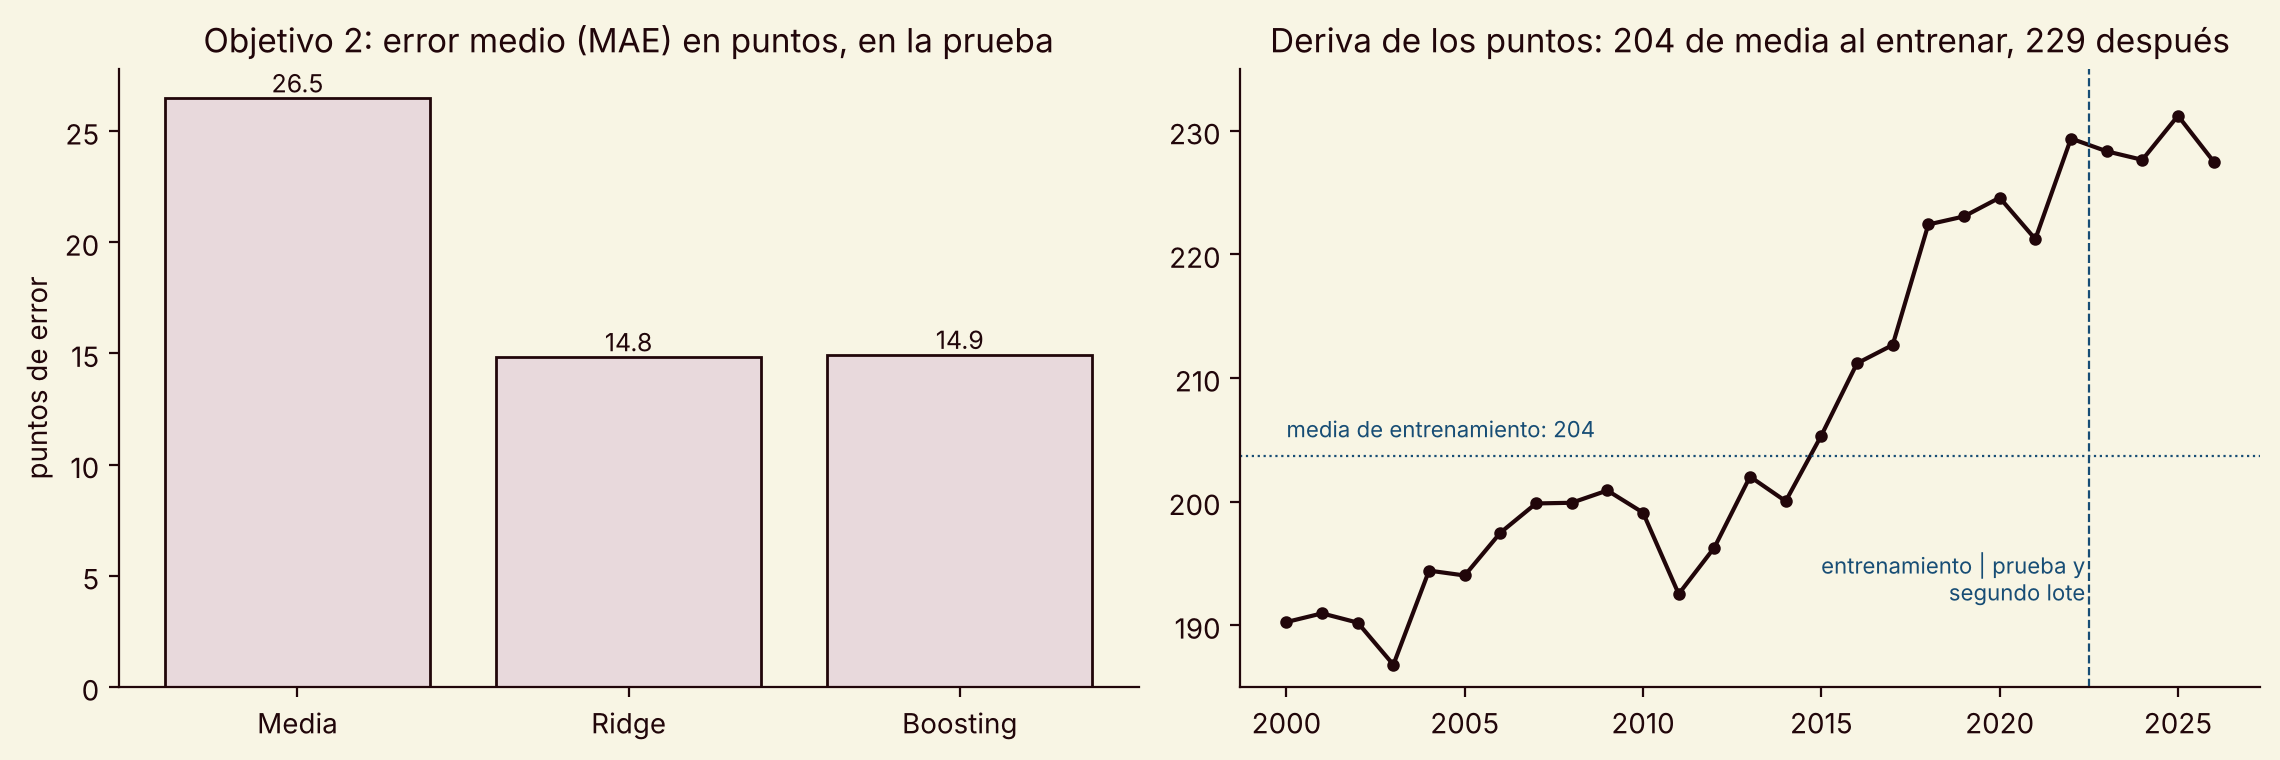

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].bar(["Media", "Ridge", "Boosting"], r2.mae_prueba, color=GRANATE_CLARO, edgecolor=GRANATE, label="prueba (2023-24)")
ax[0].set_title("Objetivo 2: error medio (MAE) en puntos, en la prueba"); ax[0].set_ylabel("puntos de error")
for p in ax[0].patches: ax[0].text(p.get_x() + p.get_width()/2, p.get_height(), f"{p.get_height():.1f}", ha="center", va="bottom", fontsize=9)
# drift: media de puntos por temporada, con los cortes
ax[1].plot(por_t.index, por_t.puntos, color=GRANATE, marker="o", ms=3.5)
ax[1].axvline(2022.5, color=AZUL, ls="--", lw=.8); ax[1].text(2022.4, 192, "entrenamiento | prueba y\nsegundo lote", ha="right", fontsize=8, color=AZUL)
ax[1].axhline(y[tr].mean(), color=AZUL, lw=.8, ls=":"); ax[1].text(2000, y[tr].mean() + 1.5, f"media de entrenamiento: {y[tr].mean():.0f}", fontsize=8, color=AZUL)
ax[1].set_ylim(185, 235); ax[1].set_title("Deriva de los puntos: 204 de media al entrenar, 229 después")
plt.tight_layout(); plt.show()

> **En cristiano:** para los puntos totales, el modelo (Ridge) se equivoca de media **≈ 14,8 puntos** en la prueba (la referencia «siempre la media» se equivoca ≈ 26,5). Hay un detalle clave: el modelo entrenó con partidos antiguos, en los que se anotaban **204** puntos de media; en el segundo lote se anotan **229**.
> Eso es **deriva de datos (data drift)**. Lo bueno: el modelo la aguanta bastante bien (su error pasa de ≈ 14,8 a ≈ 15,1) porque sus entradas son medias de los últimos 10 partidos, que se ajustan solas al ritmo actual. Lo malo: la referencia «media vieja» se queda **25 puntos por debajo** de la realidad y su error sube de ≈ 26,5 a ≈ 27,2. Con el informe de **Evidently** (siguiente entrega) mediremos esta deriva formalmente y decidiremos si **reentrenar**.

### 7.1 ¿Coincide con lo que registró MLflow?

`modelos_base.py` guarda cada modelo en **MLflow** y deja un resumen en `docs/resultados_modelos_base.csv`. Comprobamos que lo que acabamos de calcular aquí da lo mismo (diferencias de decimales aparte):

In [18]:
mf = pd.read_csv(RAIZ / "docs" / "resultados_modelos_base.csv")
chk = pd.DataFrame([
    ["Obj. 1 · regresión logística · AUC prueba", mf.query("modelo=='regresion_logistica'").prueba_auc.iloc[0], r1.auc_prueba[1]],
    ["Obj. 1 · regresión logística · acierto prueba", mf.query("modelo=='regresion_logistica'").prueba_accuracy.iloc[0], r1.acierto_prueba[1]],
    ["Obj. 1 · baseline gana local · acierto prueba", mf.query("modelo=='baseline_gana_local'").prueba_accuracy.iloc[0], r1.acierto_prueba[0]],
    ["Obj. 2 · Ridge · MAE prueba", mf.query("modelo=='ridge'").prueba_mae.iloc[0], r2.mae_prueba[1]],
    ["Obj. 2 · media de puntos, entrenamiento", mf.query("modelo=='baseline_media'").lote2_media_predicha.iloc[0], y[tr].mean()],
    ["Obj. 2 · media de puntos, segundo lote", mf.query("modelo=='ridge'").lote2_media_real.iloc[0], y[l2].mean()]],
    columns=["métrica", "MLflow (CSV del repo)", "calculado en este notebook"])
chk["diferencia"] = (chk.iloc[:, 1] - chk.iloc[:, 2]).abs()
display(chk.style.hide(axis="index").format({"MLflow (CSV del repo)": "{:.3f}", "calculado en este notebook": "{:.3f}", "diferencia": "{:.3f}"}))

métrica,MLflow (CSV del repo),calculado en este notebook,diferencia
Obj. 1 · regresión logística · AUC prueba,0.704,0.704,0.000
Obj. 1 · regresión logística · acierto prueba,0.643,0.643,0.000
Obj. 1 · baseline gana local · acierto prueba,0.540,0.540,0.000
Obj. 2 · Ridge · MAE prueba,14.827,14.827,0.000
"Obj. 2 · media de puntos, entrenamiento",203.708,203.708,0.000
"Obj. 2 · media de puntos, segundo lote",229.292,229.292,0.000


## 8. Qué falta (sin maquillar)

**Hecho y comprobado ✔**
- Ingesta a HDFS (`/nba/raw`, 3 ficheros) con el script `ingest_raw.sh`; sin datos de jugadores ni de árbitros.
- Ensuciado reproducible (semilla 42): 8 tipos de problema, 117 126 celdas, con registro de cada cambio.
- Limpieza con Hive ejecutada: duplicados, fechas, tipos, local/visitante y marcadores; resultado en Parquet.
- Tabla de modelado compacta (55 → 22 columnas) justificada con datos.
- EDA y dos modelos base con métricas que superan a las referencias: **AUC 0,704 (acierto 64,3 % frente a ≈ 54 %)** y **MAE ≈ 14,8 puntos**; deriva de puntos medida (204 → 229).

**Pendiente ⏳ (y por qué)**

| Pendiente | Situación |
|---|---|
| **Recuperación medida** (`verificar_limpieza.py`) | Falta exportar curated a CSV (`data/curated_export/`). Es la cifra más importante de la limpieza. La celda de la sección 4.1 la calcula en cuanto exista. |
| **Revisar 2 claves repetidas** en `curated.partidos` y **78 filas** de TeamStatistics sin fecha legible | Detectadas por las comprobaciones de Hive. Hay que ver si es un fallo de la limpieza o de los datos originales. |
| **Tabla de modelado desde Hive** (`04_modelado.hql`) | Escrita, pero sin ejecutar. Después se compara con la versión de Python (debe dar lo mismo). Ahora los modelos usan los CSV originales. |
| **`TeamStatisticsExtended`** | Está en HDFS y curated, pero todavía no se usa en el modelo. |
| **MLflow: capturas de la interfaz** | Los modelos ya se registran; faltan las capturas para el informe. |
| **API FastAPI** (`/predict/winner`, `/predict/total-points`) | No empezada. |
| **Drift con segundo lote real + Evidently, y decidir si reentrenar** | Por ahora solo medimos la deriva con las temporadas recientes; falta el informe de Evidently. |
| **Montaje de Hadoop automatizado y capturas desde dentro del contenedor** | Pendiente (el compañero prueba Docker, ingesta y capturas). |
| **Informe final, legal/ético, Gantt y presupuesto** | Versión v3.3 hecha; se actualiza en las siguientes entregas. |

**Riesgos que vemos:** (1) los modelos aciertan «solo» un 64 % (el baloncesto tiene mucho azar; mejorarlo mucho es difícil); (2) la deriva en puntos es fuerte, así que habrá que reentrenar con datos recientes.